
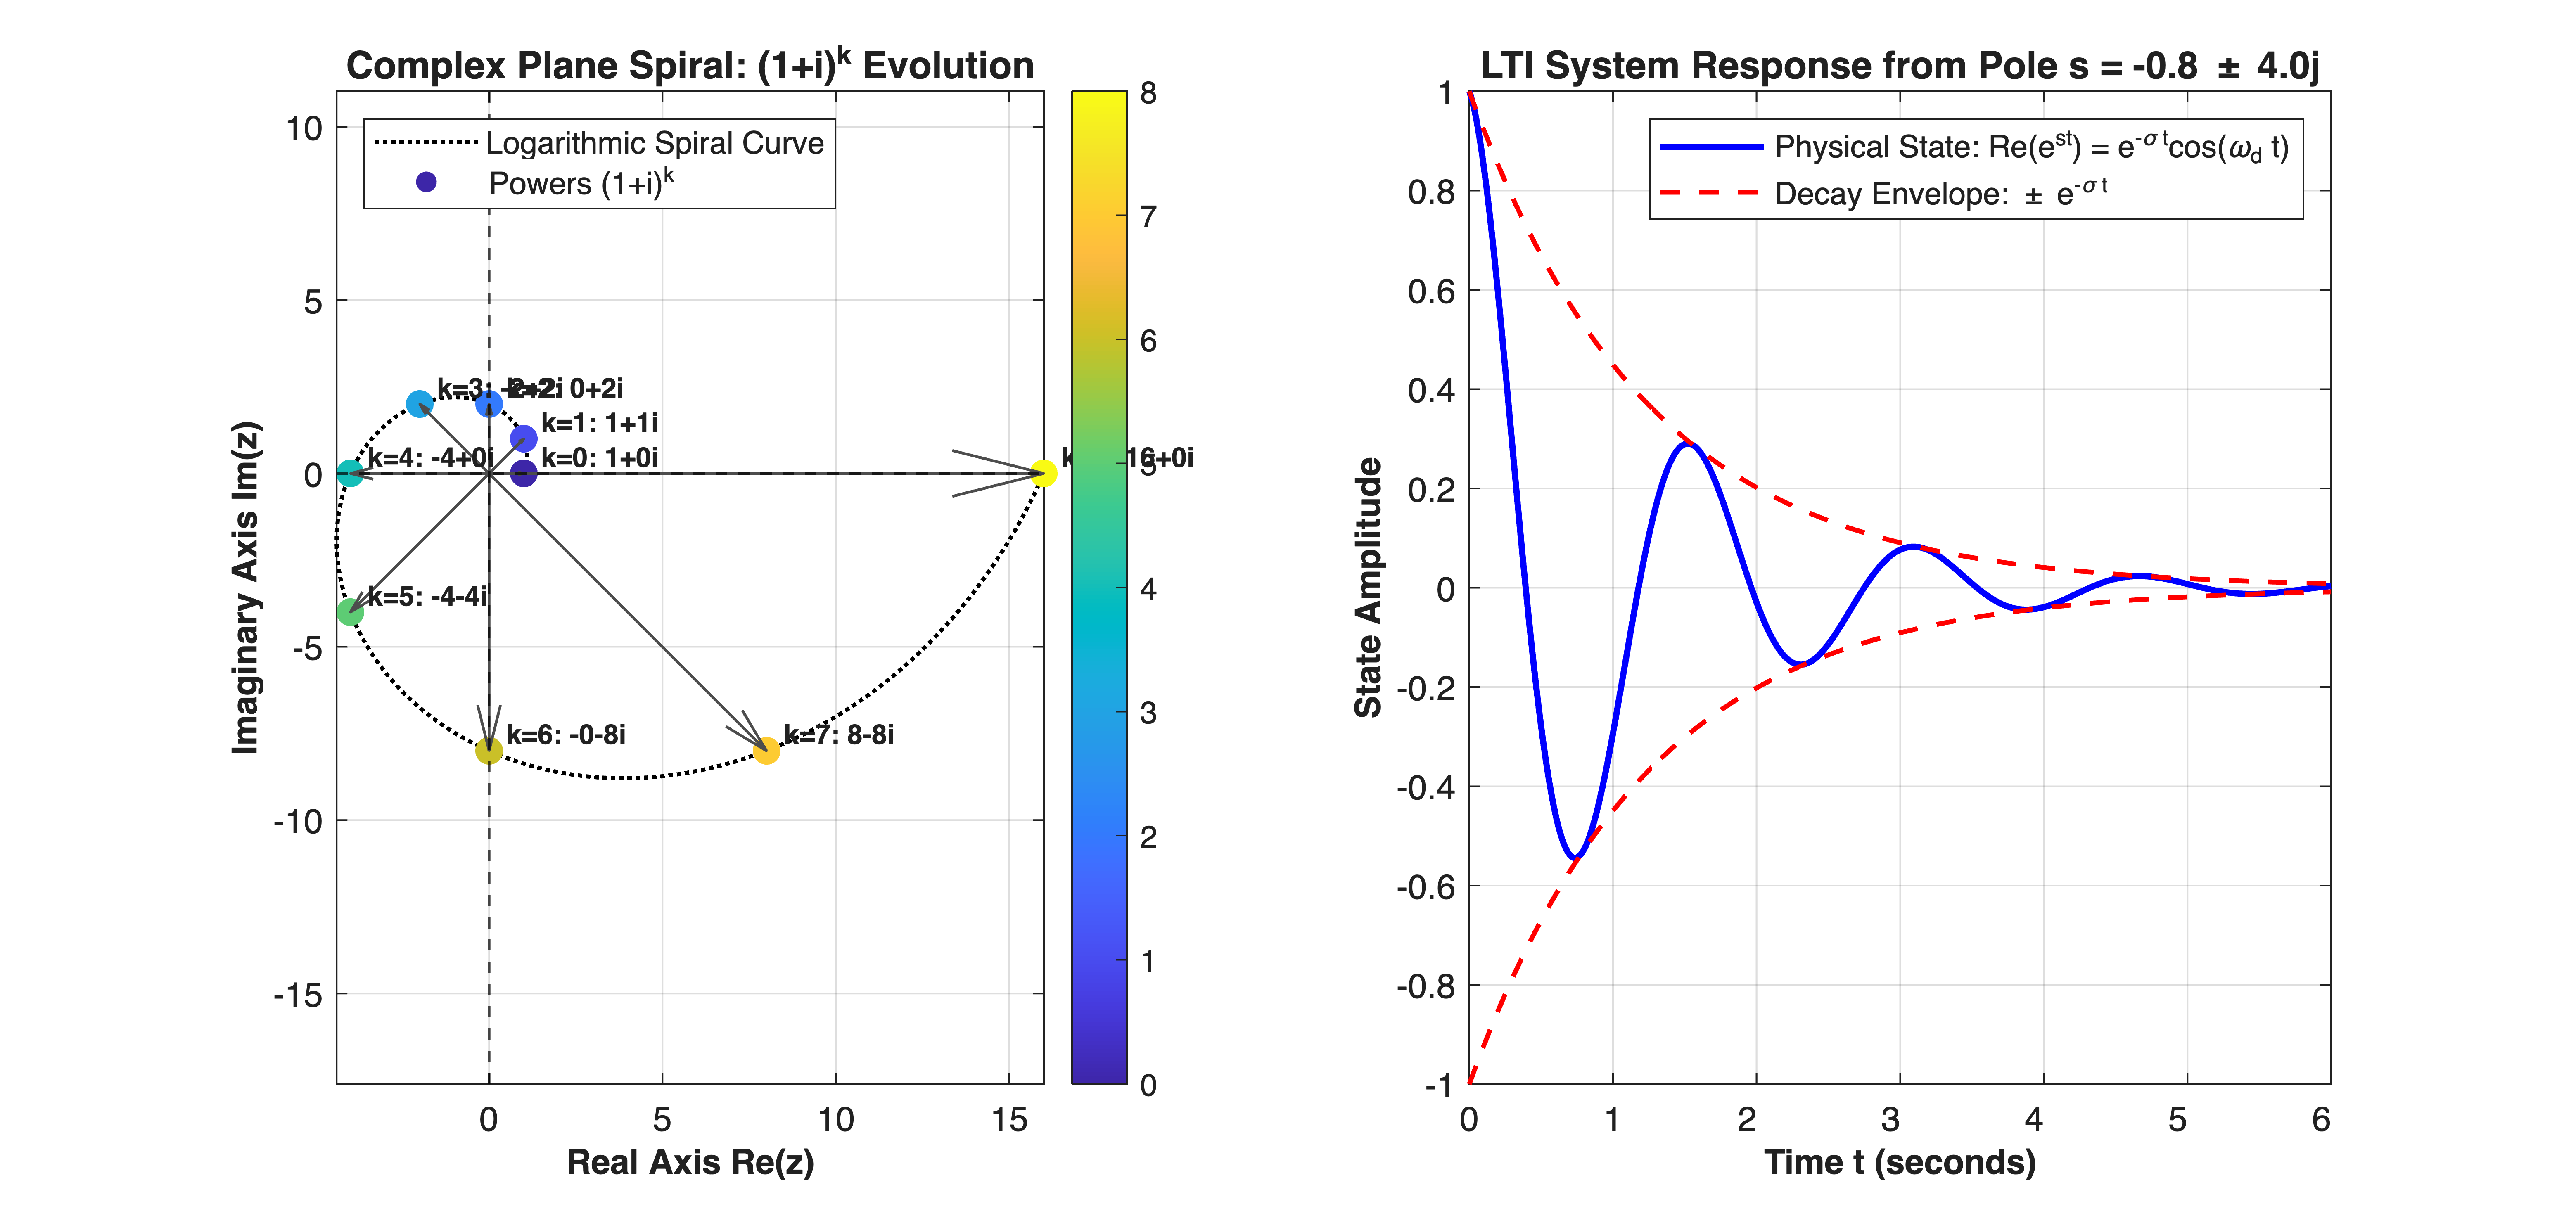

In [1]:
%% MIT 18.03 Lecture 5: Complex Algebra, Geometric Powers & Control Pole Mapping
% Description: Visualizes complex number operations:
%              1) Geometric power spiral (1+i)^k demonstrating magnitude scaling & phase rotation.
%              2) Complex conjugate pole pairs s = -sigma +/- j*omega_d mapped to temporal oscillations.
%
% % Required Toolboxes:
% %   - Base MATLAB (Core functionality)
% %   - Control System Toolbox (Optional: for pzplot/tf frequency domain functions)
%
% % MBD Concept Mapping: Demonstrates the mathematical foundation of frequency response:
% %                      Magnitudes multiply (|w*z| = |w|*|z|), angles add (Arg(w*z) = Arg(w) + Arg(z)).
% %                      Maps complex conjugate poles in the s-plane to damped harmonic oscillations.


clear; clc; close all;


%% =========================================================================
%% Part 1: Lecture Benchmark - Geometric Power Spiral of (1+i)^k
%% =========================================================================
base_z = 1 + 1i; % From Lecture 5 Section [3]
k_powers = 0:8;
z_series = base_z .^ k_powers;


figure('Color', [1 1 1], 'Position', [100, 100, 1100, 520]);


% Subplot 1: Complex Plane Trajectory (Spiral Expansion)
subplot(1, 2, 1);
hold on; grid on; box on;


% Plot origin axes
xline(0, 'k--', 'LineWidth', 0.8, 'HandleVisibility', 'off');
yline(0, 'k--', 'LineWidth', 0.8, 'HandleVisibility', 'off');


% Plot continuous logarithmic spiral interpolation
theta_fine = linspace(0, 8 * pi/4, 400);
r_fine = (sqrt(2)) .^ (theta_fine / (pi/4));
z_spiral = r_fine .* exp(1i * theta_fine);
plot(real(z_spiral), imag(z_spiral), 'k:', 'LineWidth', 1.2, ...
    'DisplayName', 'Logarithmic Spiral Curve');


% Plot discrete power points
scatter(real(z_series), imag(z_series), 65, k_powers, 'filled', ...
    'DisplayName', 'Powers (1+i)^k');
colormap(gca, 'parula');
colorbar;


% Draw vector arrows from origin to each power
for k = 1:length(z_series)
    quiver(0, 0, real(z_series(k)), imag(z_series(k)), 0, ...
        'Color', [0.3 0.3 0.3], 'LineWidth', 0.8, 'MaxHeadSize', 0.5, ...
        'HandleVisibility', 'off');
    text(real(z_series(k)) + 0.5, imag(z_series(k)) + 0.5, ...
        sprintf('k=%d: %.0f%+0.0fi', k-1, real(z_series(k)), imag(z_series(k))), ...
        'FontSize', 8, 'FontWeight', 'bold');
end


axis equal;
xlabel('Real Axis Re(z)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Imaginary Axis Im(z)', 'FontSize', 10, 'FontWeight', 'bold');
title('Complex Plane Spiral: (1+i)^k Evolution', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 9);


%% =========================================================================
%% Part 2: MBD Pole-Zero Dynamics: s = -sigma +/- j*omega_d
%% =========================================================================
% Dynamic parameters of a continuous second-order system pole pair
sigma = 0.8;      % Real attenuation rate (Envelope decay)
omega_d = 4.0;    % Damped natural frequency (Oscillation rate)
t = linspace(0, 6, 600);


% State trajectory of the continuous oscillatory mode
pole_pos = -sigma + 1i * omega_d;
x_mode = exp(pole_pos * t); % Complex response: exp(-sigma*t) * exp(j*omega_d*t)


% Subplot 2: Temporal Damped Oscillation Generated by Complex Pole
subplot(1, 2, 2);
hold on; grid on; box on;


% Real projection (physical measurable state)
plot(t, real(x_mode), 'b-', 'LineWidth', 1.8, ...
    'DisplayName', 'Physical State: Re(e^{st}) = e^{-\sigma t}cos(\omega_d t)');


% Exponential envelope dictated by Re(s) = -sigma
envelope_upper = exp(-sigma * t);
plot(t, envelope_upper, 'r--', 'LineWidth', 1.4, ...
    'DisplayName', 'Decay Envelope: \pm e^{-\sigma t}');
plot(t, -envelope_upper, 'r--', 'LineWidth', 1.4, 'HandleVisibility', 'off');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State Amplitude', 'FontSize', 10, 'FontWeight', 'bold');
title(sprintf('LTI System Response from Pole s = -%.1f \\pm %.1fj', sigma, omega_d), ...
    'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 9);

In [2]:


fprintf('=== Complex Number to Dynamic System Pole Mapping ===\n');

=== Complex Number to Dynamic System Pole Mapping ===

In [3]:
fprintf('Base Number       : 1 + 1i -> Mag = %.4f, Arg = %.4f rad (45 deg)\n', abs(base_z), angle(base_z));

Base Number       : 1 + 1i -> Mag = 1.4142, Arg = 0.7854 rad (45 deg)

In [4]:
fprintf('(1+i)^4 Result    : %.4f + %.4fi (Analytical: -4)\n', real(base_z^4), imag(base_z^4));

(1+i)^4 Result    : -4.0000 + 0.0000i (Analytical: -4)

In [5]:
fprintf('Conjugate Root    : s = -%.2f +/- %.2fi\n', sigma, omega_d);

Conjugate Root    : s = -0.80 +/- 4.00i

In [6]:
fprintf('Time Constant tau : %.4f s\n', 1/sigma);

Time Constant tau : 1.2500 s

In [7]:
fprintf('Oscillation Period: %.4f s\n', 2*pi/omega_d);

Oscillation Period: 1.5708 s

In [8]:
fprintf('=====================================================\n');